# 2. What the signals look like

Before any classifier we look at the signals of our two first datasets:

- **Cluster**: a machine slides a probe on 72 surfaces at 5 speeds;
- **LMT108**: a person slides a steel tip by hand on 36 surfaces.

Both have the sound (microphone) and the vibration (accelerometer) of each scrape.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import ndimage, signal
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.io import wavfile
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import NMF, PCA
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture

FAMILIES = ["wood", "metal", "textile", "polymer"]
COLORS = {"wood": "tab:blue", "metal": "tab:orange", "textile": "tab:green", "polymer": "tab:olive"}
CLUSTER = Path("data/cluster/cluster_haptic_texture_dataset/sensor_data")
LMT108 = Path("data/lmt108/LMT_108_SurfaceMaterials_Database")

## A few scrapes

One surface per family. Top: spectrogram of the sound. Bottom: spectrogram of the vibration (the axis that moves
the most).

In Cluster the probe lands, slides at a constant speed, then leaves. In LMT108 the hand moves freely.

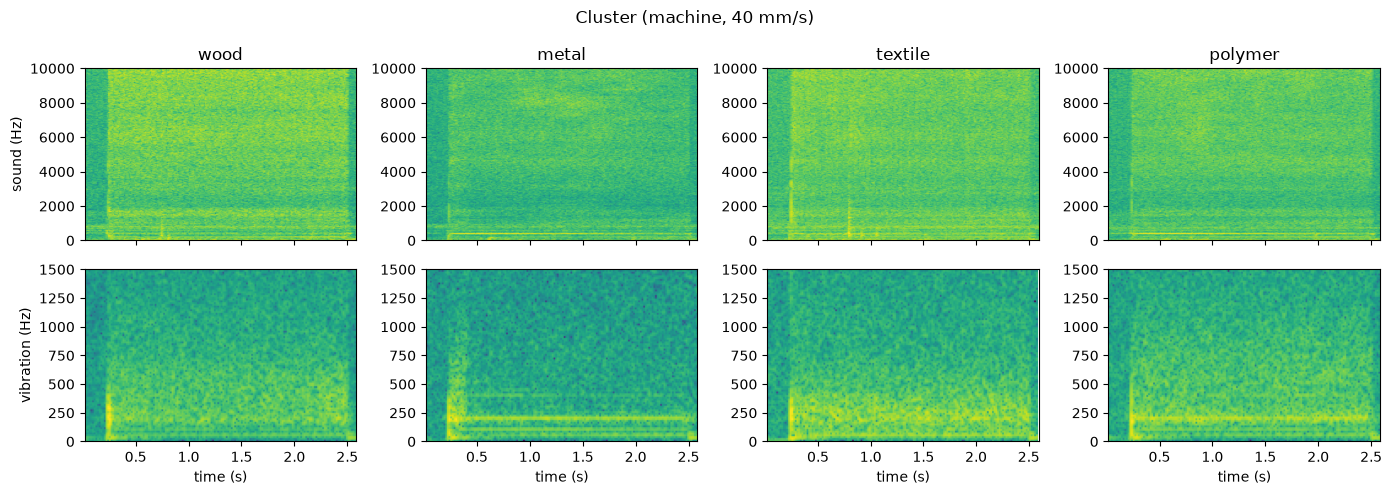

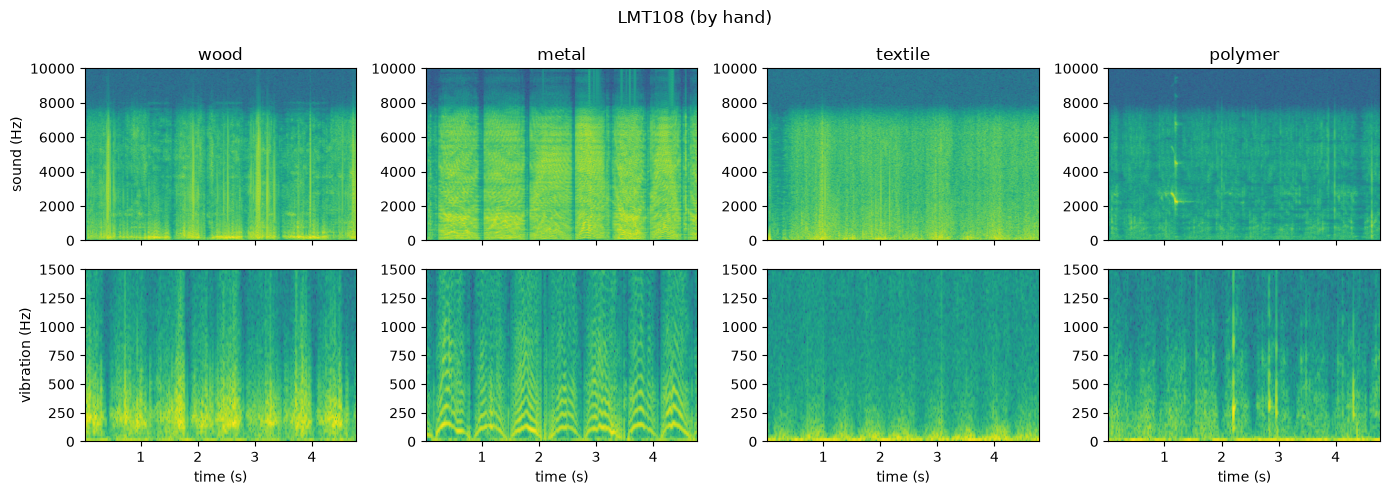

In [2]:
def read_cluster(name):
    # name = surface_direction_speed_force_repeat. Sound at 44.1 kHz and vibration at 8 kHz (3 axes).
    surface = name.split("_")[0]
    audio = wavfile.read(CLUSTER / "audio" / surface / f"{name}.wav")[1].astype(float)
    if audio.ndim > 1:
        audio = audio[:, 0]
    values = np.loadtxt(CLUSTER / "accel" / surface / f"{name}.csv", delimiter=",", skiprows=1)
    times = np.arange(values[0, 0], values[-1, 0], 1 / 8000)
    accel = np.column_stack([np.interp(times, values[:, 0], values[:, axis]) for axis in [1, 2, 3]])
    return audio, accel - accel.mean(axis=0)


def read_lmt108(surface, trial="train1"):
    audio = wavfile.read(LMT108 / "SoundScans/Movement/Training" / f"{surface}_Sound_Movement_{trial}.wav")[1].astype(float)
    if audio.ndim > 1:
        audio = audio[:, 0]
    folder = LMT108 / "AccelScansComponents/Movement/Training"
    accel = np.column_stack([np.loadtxt(folder / f"{surface}_Movement_{axis}_{trial}.txt") for axis in "XYZ"])
    accel = signal.resample_poly(accel, 4, 5, axis=0)  # 10 kHz -> 8 kHz
    return audio, accel - accel.mean(axis=0)


def main_axis(accel):
    return accel[:, np.argmax(accel.var(axis=0))]


examples = {
    "Cluster (machine, 40 mm/s)": [(f, read_cluster(f"{s}_0_40_500_0")) for f, s in [("wood", "0"), ("metal", "65"), ("textile", "87"), ("polymer", "49")]],
    "LMT108 (by hand)": [(f, read_lmt108(s)) for f, s in [("wood", "G4Beech_0"), ("metal", "G1ProfiledAluminumPlate"), ("textile", "G6Towel"), ("polymer", "G3AcrylicGlass")]],
}
for title, recordings in examples.items():
    fig, axes = plt.subplots(2, 4, figsize=(14, 5), sharex="col")
    for column, (family, (audio, accel)) in enumerate(recordings):
        axes[0, column].specgram(audio, NFFT=2048, Fs=44100, noverlap=1536)
        axes[0, column].set_ylim(0, 10000)
        axes[0, column].set_title(family)
        axes[1, column].specgram(main_axis(accel), NFFT=512, Fs=8000, noverlap=384)
        axes[1, column].set_ylim(0, 1500)
        axes[1, column].set_xlabel("time (s)")
    axes[0, 0].set_ylabel("sound (Hz)")
    axes[1, 0].set_ylabel("vibration (Hz)")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig("results/signals_examples_" + title.split()[0].lower() + ".png", dpi=110)

## One spectrum per recording

`data.ipynb` computes one power spectrum per recording (Welch), for the sound and for the vibration, on the part
where the probe touches the surface.

In [3]:
saved = np.load("cache/spectra.npz", allow_pickle=True)
spectra = {"sound": saved["sound"], "vibration": saved["vibration"]}
info = pd.DataFrame({c: saved[c] for c in saved.files if c not in spectra})

FREQ = {"sound": np.fft.rfftfreq(8192, 1 / 44100)[:2049], "vibration": np.fft.rfftfreq(1600, 1 / 8000)}
BAND = {"sound": (100, 8000), "vibration": (10, 600)}

info.groupby("dataset").agg(recordings=("family", "size"), surfaces=("surface", "nunique"))

,recordings,surfaces
dataset,,
cluster,11520,72
lmt108,720,36


## Machine noise in Cluster

We take the median spectrum of all the Cluster surfaces at each speed. What is common to all surfaces is probably
not the surface. If we plot against frequency / speed, the peaks line up: they sit at multiples of 0.875 per mm,
so f = 3.5 x speed for the strongest one. This looks like the drive of the machine.

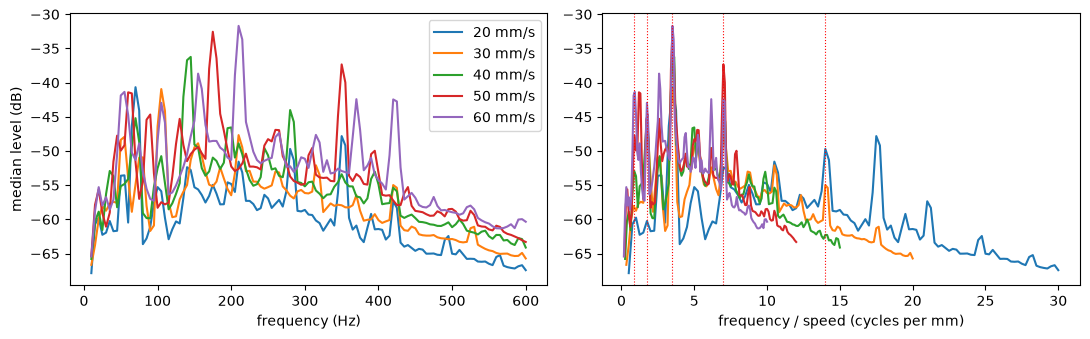

In [4]:
cluster = (info.dataset == "cluster").to_numpy()
speeds = [20, 30, 40, 50, 60]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for v in speeds:
    median = np.median(spectra["vibration"][cluster & (info.velocity == v).to_numpy()], axis=0)
    shown = (FREQ["vibration"] >= 10) & (FREQ["vibration"] <= 600)
    axes[0].plot(FREQ["vibration"][shown], 10 * np.log10(median[shown]), label=f"{v} mm/s")
    axes[1].plot(FREQ["vibration"][shown] / v, 10 * np.log10(median[shown]))
for k in [0.875, 1.75, 3.5, 7, 14]:
    axes[1].axvline(k, color="red", linestyle=":", linewidth=0.8)
axes[0].set_xlabel("frequency (Hz)")
axes[1].set_xlabel("frequency / speed (cycles per mm)")
axes[0].set_ylabel("median level (dB)")
axes[0].legend()
plt.tight_layout()
plt.savefig("results/signals_machine_lines.png", dpi=120)

In [5]:
# share of the 10-600 Hz vibration energy that sits within 10 Hz of a multiple of 3.5 x speed
for v in speeds:
    median = np.median(spectra["vibration"][cluster & (info.velocity == v).to_numpy()], axis=0)
    f = FREQ["vibration"]
    in_band = (f >= 10) & (f <= 600)
    near_line = np.abs(f / (3.5 * v) - np.round(f / (3.5 * v))) * 3.5 * v <= 10
    print(v, "mm/s:", round(median[in_band & near_line].sum() / median[in_band].sum(), 2))

20 mm/s: 0.73
30 mm/s: 0.45
40 mm/s: 0.61
50 mm/s: 0.63
60 mm/s: 0.54


### Can we separate the machine from the surface?

We try with NMF (non-negative matrix factorization) on the vibration spectrograms of eight surfaces, two per family,
put side by side. NMF writes the spectrogram as a sum of 12 fixed spectra ("templates"), each with its own level
over time.

A template that is narrow in frequency and active on **all** the surfaces is probably the machine.

width of each template (Hz): [ 62  16  16 172  47  47  47  78  47  47  62 109]
presence on every surface:   [0.21 0.26 0.28 0.18 0.31 0.21 0.15 0.12 0.27 0.31 0.24 0.19]
templates that look like the machine: [1 2]


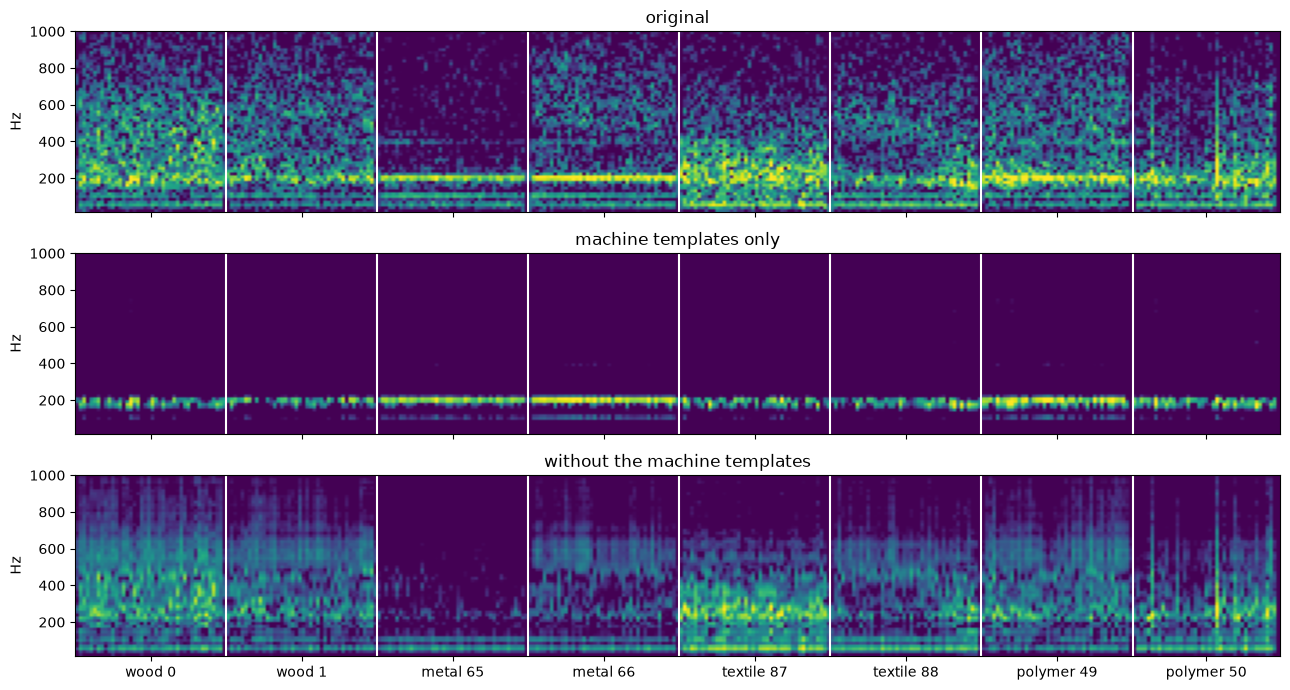

In [6]:
chosen = [("wood", "0"), ("wood", "1"), ("metal", "65"), ("metal", "66"), ("textile", "87"), ("textile", "88"), ("polymer", "49"), ("polymer", "50")]
blocks = []
for family, surface in chosen:
    audio, accel = read_cluster(f"{surface}_0_40_500_0")
    middle = main_axis(accel)[len(accel) // 4 : -len(accel) // 4]  # where the probe slides
    freq, _, stft = signal.stft(middle, 8000, nperseg=512)
    blocks.append(np.abs(stft[(freq >= 10) & (freq <= 1000)]))
freq = freq[(freq >= 10) & (freq <= 1000)]
together = np.hstack(blocks)
ends = np.cumsum([b.shape[1] for b in blocks])

nmf = NMF(12, beta_loss="kullback-leibler", solver="mu", max_iter=2000, init="nndsvda", random_state=0)
templates = nmf.fit_transform(together)
levels = nmf.components_ * templates.sum(axis=0)[:, None]
templates = templates / templates.sum(axis=0)

# width: how many Hz hold half of the template. presence: its weakest surface compared with its strongest.
width = (np.sort(templates, axis=0)[::-1].cumsum(axis=0) < 0.5).sum(axis=0) * (freq[1] - freq[0])
level_on_surface = np.array([part.mean(axis=1) for part in np.split(levels, ends[:-1], axis=1)])
presence = level_on_surface.min(axis=0) / level_on_surface.max(axis=0)
machine = (width < 30) & (presence > 0.2)
print("width of each template (Hz):", width.round().astype(int))
print("presence on every surface:  ", presence.round(2))
print("templates that look like the machine:", np.flatnonzero(machine))

fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
parts = [together, templates[:, machine] @ levels[machine], templates[:, ~machine] @ levels[~machine]]
low, high = np.log(np.percentile(together, 30)), np.log(np.percentile(together, 99.5))
for ax, part, title in zip(axes, parts, ["original", "machine templates only", "without the machine templates"]):
    ax.imshow(np.log(part + 1e-6), aspect="auto", origin="lower", extent=[0, together.shape[1], freq[0], freq[-1]], vmin=low, vmax=high)
    ax.vlines(ends[:-1], freq[0], freq[-1], color="white")
    ax.set_title(title)
    ax.set_ylabel("Hz")
axes[2].set_xticks((np.r_[0, ends[:-1]] + ends) / 2, [f"{f} {s}" for f, s in chosen])
plt.tight_layout()
plt.savefig("results/signals_machine_nmf.png", dpi=110)

NMF does find narrow templates that are present on every surface. It is a candidate for the machine noise, not a
proof: we have no recording of the machine alone.

For the rest we use a simpler removal: at each speed we find the narrow peaks of the median spectrum (more than 5 dB
above their neighbours) and replace them by a straight line between their two sides.

In [7]:
def without_machine_lines(kind, filter_width):
    clean = spectra[kind].copy()
    in_band = (FREQ[kind] >= BAND[kind][0]) & (FREQ[kind] <= BAND[kind][1])
    for v in speeds:
        rows = np.flatnonzero(cluster & (info.velocity == v).to_numpy())
        level = 10 * np.log10(np.median(spectra[kind][rows], axis=0))
        prominence = level - ndimage.median_filter(level, filter_width)
        peaks, _ = signal.find_peaks(np.where(in_band, prominence, 0), height=5)
        masked = np.zeros(len(level), dtype=bool)
        for peak in peaks:
            masked[peak - 2 : peak + 3] = True
        log_power = pd.DataFrame(np.log(spectra[kind][rows]))
        log_power.loc[:, masked] = np.nan
        clean[rows] = np.exp(log_power.interpolate(axis=1).to_numpy())
    return clean


clean = {"sound": without_machine_lines("sound", 41), "vibration": without_machine_lines("vibration", 15)}

## Spectral shapes

To compare recordings we sum the power in third-octave bands, in dB, and remove the mean level of each recording.
What is left is the **shape** of the spectrum, not how loud it is.

In [8]:
def third_octaves(power, freq, low, high):
    centers = 1000 * 2.0 ** (np.arange(-30, 30) / 3)
    centers = centers[(centers / 2 ** (1 / 6) >= low) & (centers * 2 ** (1 / 6) <= high)]
    levels = {}
    for c in centers:
        inside = (freq >= c / 2 ** (1 / 6)) & (freq < c * 2 ** (1 / 6))
        if inside.sum() >= 2:
            levels[int(round(c))] = 10 * np.log10(power[:, inside].sum(axis=1))
    return pd.DataFrame(levels)


def shapes_of(power):
    parts = []
    for kind in ["sound", "vibration"]:
        levels = third_octaves(power[kind], FREQ[kind], *BAND[kind])
        parts.append(levels.sub(levels.mean(axis=1), axis=0).add_prefix(kind + " "))
    return pd.concat(parts, axis=1)


shapes = shapes_of(clean)

# for the classifiers of notebook 3 we keep the machine lines: removing them uses all the surfaces at once,
# so it should not be done before splitting training and test
pd.concat([info, shapes_of(spectra)], axis=1).to_csv("cache/spectral_shapes.csv", index=False)
shapes.shape

(12240, 30)

## Do the families look different?

Median shape of each family, in each dataset.

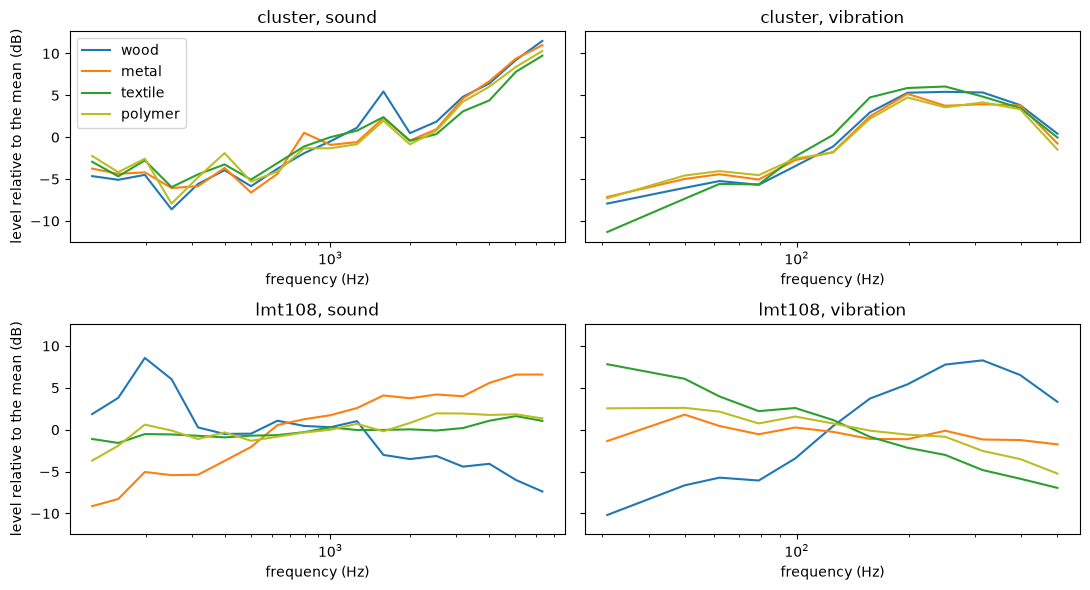

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharey=True)
for i, dataset in enumerate(["cluster", "lmt108"]):
    for j, kind in enumerate(["sound", "vibration"]):
        columns = [c for c in shapes.columns if c.startswith(kind)]
        bands = [int(c.split()[1]) for c in columns]
        for family in FAMILIES:
            rows = ((info.dataset == dataset) & (info.family == family)).to_numpy()
            per_surface = shapes.loc[rows, columns].groupby(info.surface[rows].to_numpy()).median()
            axes[i, j].plot(bands, per_surface.median(), color=COLORS[family], label=family)
        axes[i, j].set_xscale("log")
        axes[i, j].xaxis.set_minor_formatter(plt.NullFormatter())
        axes[i, j].set_title(f"{dataset}, {kind}")
        axes[i, j].set_xlabel("frequency (Hz)")
    axes[i, 0].set_ylabel("level relative to the mean (dB)")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("results/signals_family_spectra.png", dpi=120)

## What changes the spectrum the most?

Cluster records every surface at 5 speeds, 2 forces and several directions. For each frequency band we ask which
factor explains the variance of the level: the surface, the speed, both together, the direction, the force.
The black line is the family: it is a part of what the surface explains.

sound | mean over the bands: {'surface': 0.33, 'speed': 0.32, 'surface x speed': 0.03, 'direction': 0.08, 'force': 0.01, 'rest': 0.23} | family: 0.05
vibration | mean over the bands: {'surface': 0.17, 'speed': 0.26, 'surface x speed': 0.04, 'direction': 0.23, 'force': 0.0, 'rest': 0.3} | family: 0.1


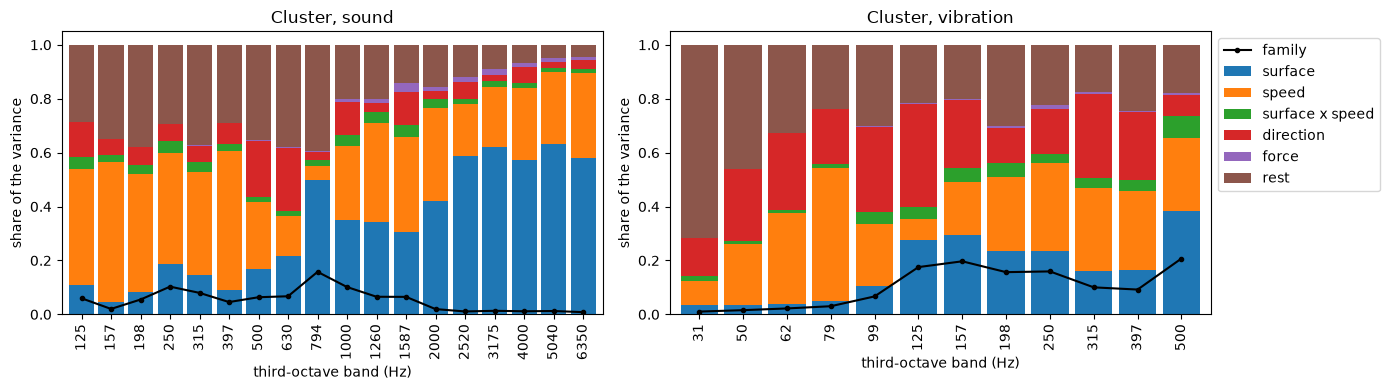

In [10]:
cluster_info = info[cluster].reset_index(drop=True)


def explained(levels, factors):
    means = levels.groupby([cluster_info[f] for f in factors]).transform("mean")
    return means.var() / levels.var()


fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, kind in zip(axes, ["sound", "vibration"]):
    levels = third_octaves(clean[kind][cluster], FREQ[kind], *BAND[kind])
    table = pd.DataFrame({"surface": explained(levels, ["surface"]), "speed": explained(levels, ["velocity"])})
    table["surface x speed"] = explained(levels, ["surface", "velocity"]) - table.surface - table.speed
    table["direction"] = explained(levels, ["direction"])
    table["force"] = explained(levels, ["force"])
    table["rest"] = 1 - table.sum(axis=1)
    family = explained(levels, ["family"])
    table.plot.bar(stacked=True, ax=ax, width=0.85, legend=False)
    ax.plot(range(len(family)), family, color="black", marker=".", label="family")
    ax.set_title(f"Cluster, {kind}")
    ax.set_xlabel("third-octave band (Hz)")
    ax.set_ylabel("share of the variance")
    shares = {k: round(float(v), 2) for k, v in table.mean().items()}
    print(kind, "| mean over the bands:", shares, "| family:", round(float(family.mean()), 2))
axes[1].legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig("results/signals_variance.png", dpi=120)

## Family or dataset?

A PCA of all the shapes. For Cluster we keep one direction and one force so both datasets weigh about the same.

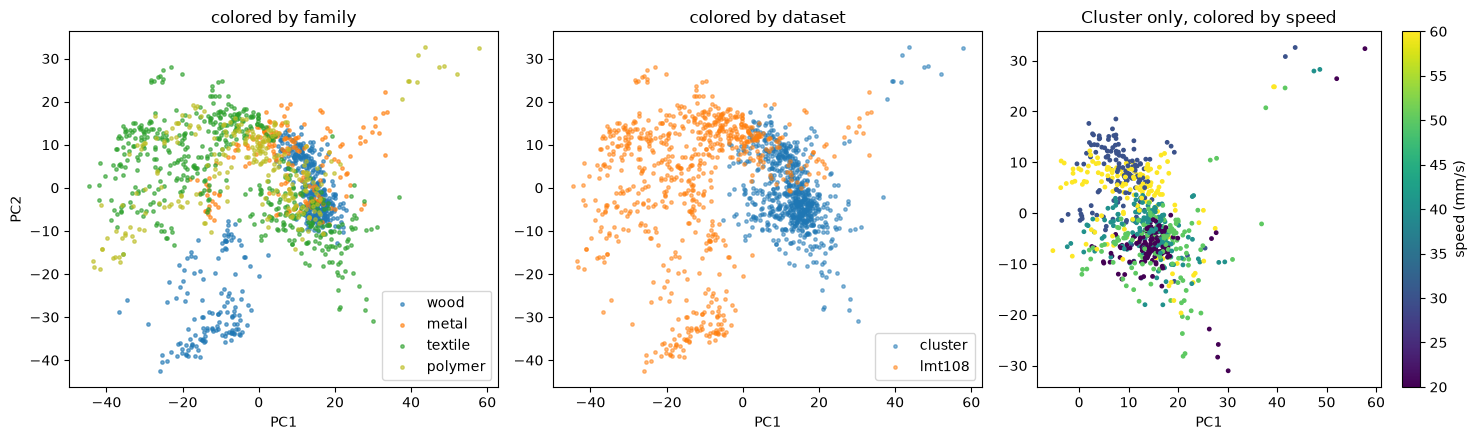

In [11]:
kept = ((info.dataset == "lmt108") | ((info.direction == 0) & (info.force == 500))).to_numpy()
points = info[kept].reset_index(drop=True)
xy = PCA(2).fit_transform(shapes[kept])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for family in FAMILIES:
    rows = (points.family == family).to_numpy()
    axes[0].scatter(xy[rows, 0], xy[rows, 1], s=6, alpha=0.6, color=COLORS[family], label=family)
for dataset in ["cluster", "lmt108"]:
    rows = (points.dataset == dataset).to_numpy()
    axes[1].scatter(xy[rows, 0], xy[rows, 1], s=6, alpha=0.5, label=dataset)
rows = (points.dataset == "cluster").to_numpy()
dots = axes[2].scatter(xy[rows, 0], xy[rows, 1], s=6, c=points.velocity[rows], cmap="viridis")
plt.colorbar(dots, ax=axes[2], label="speed (mm/s)")
for ax, title in zip(axes, ["colored by family", "colored by dataset", "Cluster only, colored by speed"]):
    ax.set_title(title)
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.savefig("results/signals_pca.png", dpi=120)

The same PCA done inside each dataset: does the family show up when the dataset is not in the way?

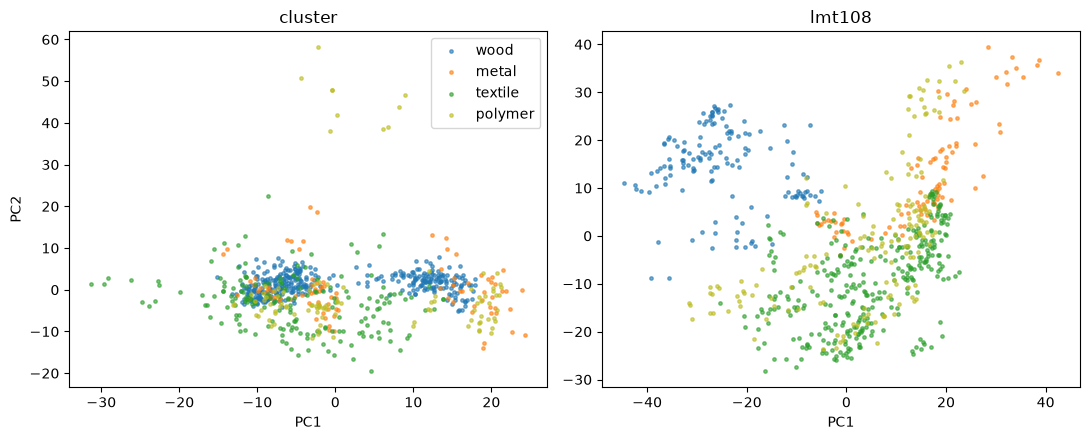

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, dataset in zip(axes, ["cluster", "lmt108"]):
    inside = (points.dataset == dataset).to_numpy()
    xy_inside = PCA(2).fit_transform(shapes[kept][inside])
    for family in FAMILIES:
        rows = (points.family[inside] == family).to_numpy()
        ax.scatter(xy_inside[rows, 0], xy_inside[rows, 1], s=6, alpha=0.6, color=COLORS[family], label=family)
    ax.set_title(dataset)
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend()
plt.tight_layout()
plt.savefig("results/signals_pca_per_dataset.png", dpi=120)

## Clustering the surfaces

No labels here: we group the surfaces (one median shape per surface) with three methods, for 2 to 10 groups, and
compare the groups with the families and with the datasets. The adjusted Rand index (ARI) is 1 for a perfect match
and 0 for random groups.

In [13]:
per_surface = shapes.groupby([info.dataset, info.family, info.surface]).median()
labels = per_surface.index.to_frame(index=False)
subsets = {
    "cluster": (labels.dataset == "cluster").to_numpy(),
    "lmt108": (labels.dataset == "lmt108").to_numpy(),
    "both": np.ones(len(labels), dtype=bool),
}


def three_methods(vectors, k):
    return {
        "k-means": KMeans(k, n_init=20, random_state=0).fit_predict(vectors),
        "Gaussian mixture": GaussianMixture(k, covariance_type="diag", n_init=5, random_state=0).fit_predict(vectors),
        "Ward": AgglomerativeClustering(k).fit_predict(vectors),
    }


rows, groups_at_4 = [], {}
for name, inside in subsets.items():
    for k in range(2, 11):
        for method, groups in three_methods(per_surface[inside], k).items():
            rows.append({"surfaces": name, "k": k, "method": method,
                         "family": adjusted_rand_score(labels.family[inside], groups),
                         "dataset": adjusted_rand_score(labels.dataset[inside], groups)})
            if k == 4 and method == "k-means":
                groups_at_4[name] = groups
clustering = pd.DataFrame(rows)
clustering.to_csv("results/signals_clustering.csv", index=False)
clustering[clustering.k == 4].round(2)

,surfaces,k,method,family,dataset
6,cluster,4,k-means,0.63,0.00
7,cluster,4,Gaussian mixture,0.74,0.00
8,cluster,4,Ward,0.74,0.00
33,lmt108,4,k-means,0.29,0.00
34,lmt108,4,Gaussian mixture,0.31,0.00
35,lmt108,4,Ward,0.29,0.00
60,both,4,k-means,0.09,0.80
61,both,4,Gaussian mixture,0.11,0.86
62,both,4,Ward,0.09,0.80


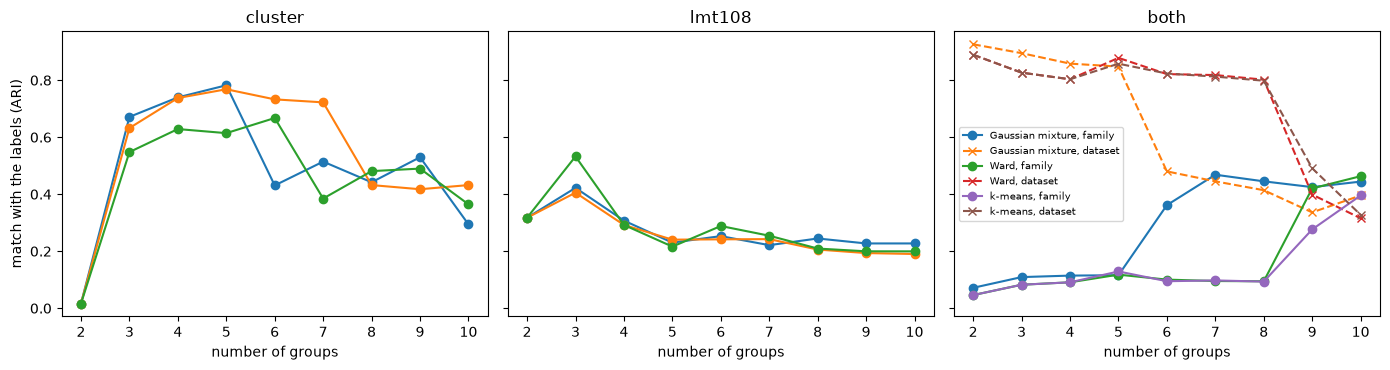

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, name in zip(axes, subsets):
    part = clustering[clustering.surfaces == name]
    for method, curve in part.groupby("method"):
        ax.plot(curve.k, curve.family, marker="o", label=f"{method}, family")
        if name == "both":
            ax.plot(curve.k, curve.dataset, marker="x", linestyle="--", label=f"{method}, dataset")
    ax.set_title(name)
    ax.set_xlabel("number of groups")
axes[0].set_ylabel("match with the labels (ARI)")
axes[2].legend(fontsize=7)
plt.tight_layout()
plt.savefig("results/signals_clustering.png", dpi=120)

What is inside the four k-means groups:

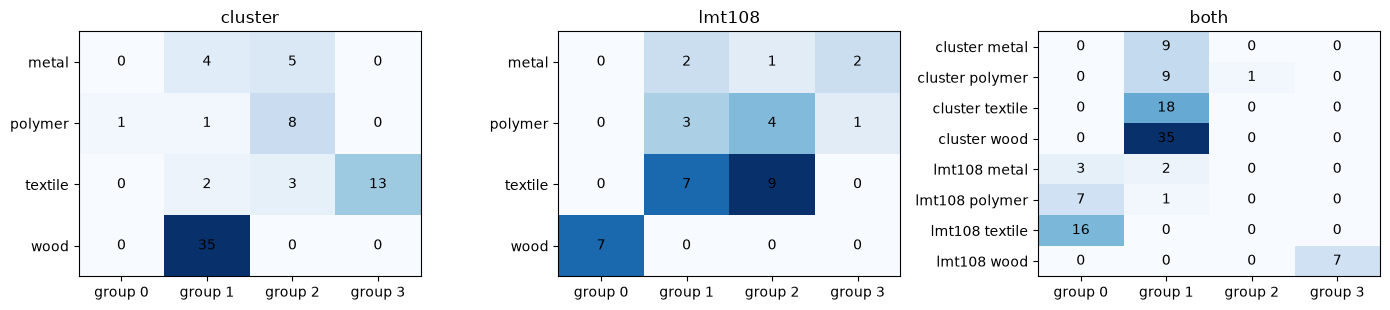

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, name in zip(axes, subsets):
    inside = labels[subsets[name]]
    truth = inside.dataset + " " + inside.family if name == "both" else inside.family
    counts = pd.crosstab(truth.to_numpy(), groups_at_4[name])
    ax.imshow(counts, cmap="Blues", aspect="auto")
    for i in range(counts.shape[0]):
        for j in range(counts.shape[1]):
            ax.text(j, i, counts.iloc[i, j], ha="center", va="center")
    ax.set_yticks(range(len(counts)), counts.index)
    ax.set_xticks(range(4), [f"group {g}" for g in range(4)])
    ax.set_title(name)
plt.tight_layout()
plt.savefig("results/signals_clustering_groups.png", dpi=120)

And the whole tree (Ward): surfaces that look alike are joined first. Under the tree, the family and the dataset of
each surface.

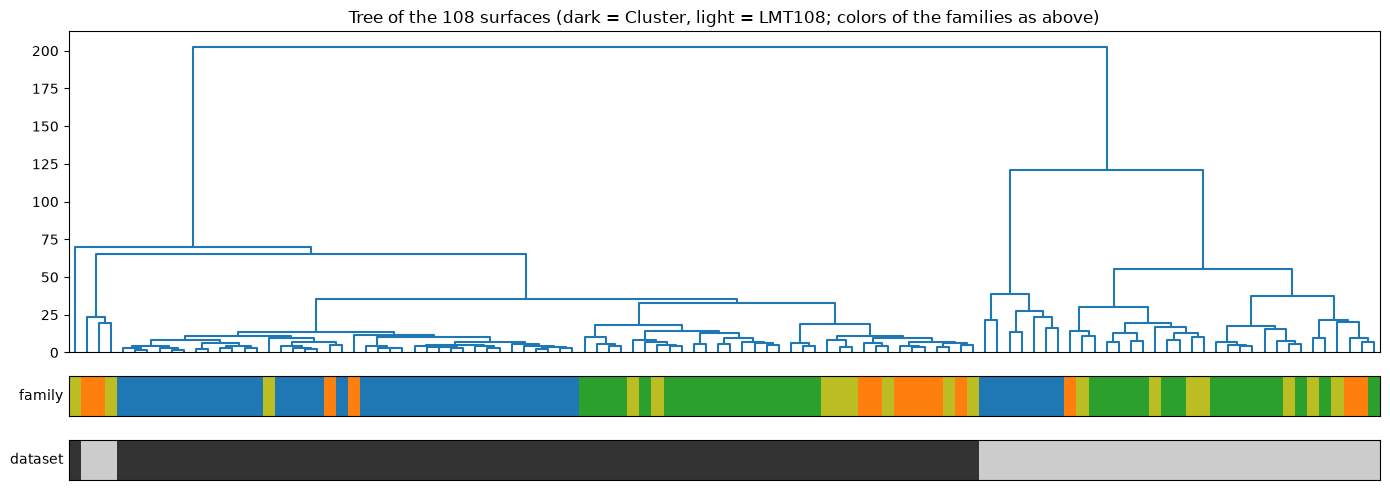

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(14, 5), gridspec_kw={"height_ratios": [8, 1, 1]})
tree = dendrogram(linkage(per_surface, "ward"), no_labels=True, color_threshold=0, ax=axes[0])
order = tree["leaves"]
family_colors = np.array([plt.matplotlib.colors.to_rgb(COLORS[f]) for f in labels.family[order]])
dataset_colors = np.array([[0.2, 0.2, 0.2] if d == "cluster" else [0.8, 0.8, 0.8] for d in labels.dataset[order]])
axes[1].imshow(family_colors[None], aspect="auto")
axes[2].imshow(dataset_colors[None], aspect="auto")
axes[1].set_ylabel("family", rotation=0, ha="right", va="center")
axes[2].set_ylabel("dataset", rotation=0, ha="right", va="center")
for ax in axes[1:]:
    ax.set_xticks([])
    ax.set_yticks([])
axes[0].set_title("Tree of the 108 surfaces (dark = Cluster, light = LMT108; colors of the families as above)")
plt.tight_layout()
plt.savefig("results/signals_clustering_tree.png", dpi=120)

## What does speed do?

Three Cluster surfaces at the five speeds:

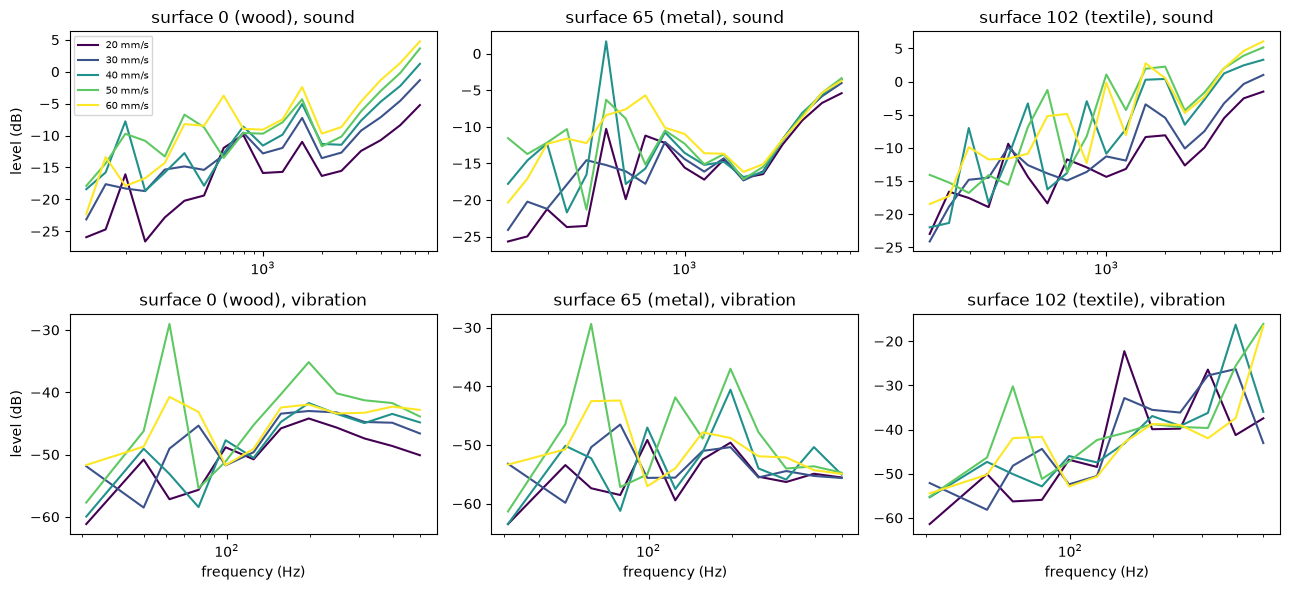

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for column, surface in enumerate(["0", "65", "102"]):
    rows = np.flatnonzero((cluster & (info.surface == surface) & (info.direction == 0) & (info.force == 500) & (info.repeat == 0)).to_numpy())
    for row, kind in enumerate(["sound", "vibration"]):
        levels = third_octaves(spectra[kind][rows], FREQ[kind], *BAND[kind])
        for i, v in zip(range(len(rows)), info.velocity[rows]):
            axes[row, column].plot(levels.columns, levels.iloc[i], label=f"{int(v)} mm/s", color=plt.cm.viridis((v - 20) / 40))
        axes[row, column].set_xscale("log")
        axes[row, column].xaxis.set_minor_formatter(plt.NullFormatter())
        axes[row, column].set_title(f"surface {surface} ({info.family[rows[0]]}), {kind}")
    axes[1, column].set_xlabel("frequency (Hz)")
axes[0, 0].set_ylabel("level (dB)")
axes[1, 0].set_ylabel("level (dB)")
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.savefig("results/signals_speed.png", dpi=120)

If speed only moved the frequencies (same bumps of the surface read faster), the spectrum at 60 mm/s would be the
spectrum at 20 mm/s shifted by a factor 3. We compare, for the same surface, the spectrum at 20 and at 60 mm/s:

- at the same frequency;
- at the same frequency / speed.

In [18]:
rows = []
for kind in ["sound", "vibration"]:
    grid = np.geomspace(BAND[kind][0], BAND[kind][1] / 3, 200)
    for _, group in info[cluster].groupby(["surface", "direction", "force", "repeat"]):
        slow = group.index[group.velocity == 20][0]
        fast = group.index[group.velocity == 60][0]
        at_20 = np.interp(grid, FREQ[kind], np.log(clean[kind][slow]))
        at_60 = np.interp(grid, FREQ[kind], np.log(clean[kind][fast]))
        at_60_shifted = np.interp(3 * grid, FREQ[kind], np.log(clean[kind][fast]))
        level = "audio_log_rms" if kind == "sound" else "accel_log_rms"
        rows.append(
            {
                "signal": kind,
                "same frequency": np.corrcoef(at_20, at_60)[0, 1],
                "same frequency / speed": np.corrcoef(at_20, at_60_shifted)[0, 1],
                "dB per doubling of speed": 20 * (info[level][fast] - info[level][slow]) / np.log2(3),
            }
        )
pd.DataFrame(rows).groupby("signal").median().round(2)

,same frequency,same frequency / speed,dB per doubling of speed
signal,,,
sound,0.45,0.02,5.37
vibration,0.29,0.08,5.58


## Do the sound and the vibration tell the same thing?

The coherence between two signals is 1 at a frequency where one can be predicted from the other, and 0 where they
are unrelated. We compute it between the sound and the vibration of the same scrape, on 80 recordings of each
dataset, after lining the two signals up in time.

cluster | median coherence between 50 and 1000 Hz: 0.099
lmt108 | median coherence between 50 and 1000 Hz: 0.01


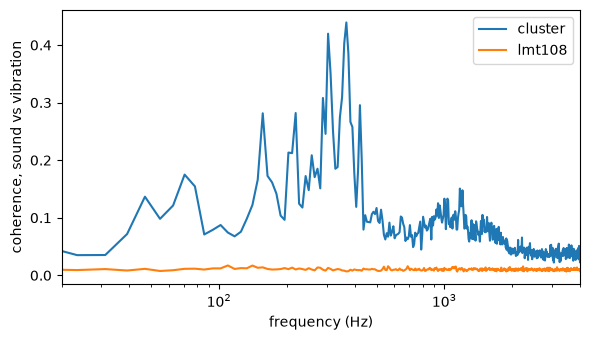

In [19]:
def coherence(audio, accel):
    # both signals at 8 kHz, in their useful band, shifted to line up, then the coherence
    audio = signal.sosfiltfilt(signal.butter(4, (100, 8000), "bandpass", fs=44100, output="sos"), audio)
    accel = signal.sosfiltfilt(signal.butter(4, (10, 600), "bandpass", fs=8000, output="sos"), accel, axis=0)
    a, b = signal.resample_poly(audio, 80, 441), main_axis(accel)
    n = min(len(a), len(b))
    a, b = a[:n], b[:n]
    lags = signal.correlation_lags(n, n)
    close = np.abs(lags) <= 800
    lag = lags[close][np.argmax(np.abs(signal.correlate(a, b, method="fft")[close]))]
    a, b = (a[lag:], b[: n - lag]) if lag >= 0 else (a[: n + lag], b[-lag:])
    return signal.coherence(a, b, 8000, nperseg=1024)[1]


rng = np.random.default_rng(0)
curves = {}
names = sorted(p.stem for p in (CLUSTER / "audio").rglob("*.wav"))
curves["cluster"] = []
for name in rng.choice(names, 80, replace=False):
    audio, accel = read_cluster(name)
    # the middle half of the recording, without the landing and the leaving of the probe
    curves["cluster"].append(coherence(audio[len(audio) // 4 : -len(audio) // 4], accel[len(accel) // 4 : -len(accel) // 4]))
files = sorted((LMT108 / "SoundScans/Movement/Training").glob("*.wav"))
picked = [f.stem.split("_Sound_Movement_") for f in rng.choice(files, 80, replace=False)]
curves["lmt108"] = [coherence(*read_lmt108(s, t)) for s, t in picked]

f = np.fft.rfftfreq(1024, 1 / 8000)
plt.figure(figsize=(6, 3.5))
for dataset, values in curves.items():
    median = np.median(values, axis=0)
    plt.plot(f, median, label=dataset)
    print(dataset, "| median coherence between 50 and 1000 Hz:", round(float(np.median(median[(f >= 50) & (f <= 1000)])), 3))
plt.xscale("log")
plt.xlim(20, 4000)
plt.xlabel("frequency (Hz)")
plt.ylabel("coherence, sound vs vibration")
plt.legend()
plt.tight_layout()
plt.savefig("results/signals_coherence.png", dpi=120)

## What we see

- With the two datasets together, a clustering finds the **dataset** (ARI 0.80 to 0.86 with four groups), not the
  family (about 0.1). The PCA shows the same thing.
- Inside one dataset the families do show up. In LMT108 their median shapes are very different (wood has a bump
  around 200 Hz). In Cluster the median shapes look alike, yet a clustering still isolates wood and most textiles
  (ARI 0.63 to 0.74); metal and polymer stay mixed.
- In Cluster the speed changes the spectrum as much as the surface does (about a third of the variance each for the
  sound). The family explains only 5 to 10 %.
- The Cluster vibration contains lines that follow the speed of the machine (45 to 73 % of the energy between 10 and
  600 Hz). NMF finds two narrow templates present on every surface: a candidate for this machine noise.
- Speed is not a simple shift of the frequencies: spectra match better at the same frequency. The level rises by
  about 5 dB each time the speed doubles.
- Sound and vibration are almost unrelated in LMT108 (coherence about 0.01) and a little more in Cluster (0.10).
  They are two different views of the scrape, not twice the same.

For the models this means: remove the level, keep both signals, and do not expect a model trained on one dataset to
work on the other.